In [7]:
import matplotlib.pyplot as plt
import numpy as np
import stim
import tempfile
import os
import sinter

from honeycomb import CSSHoneycomb
from operations import Detector
from testing.codespace_distance import check_noiseless, effective_distance


from sims import run_experiment, build_circuit, check_circuit,estimate_logical_error_rate
from collections import defaultdict
import json

from phenom_honeycomb import build_phenomenological_circuit, PhenomenologicalHoneycomb, PhenomenologicalNoise 

The goal of this notebook is to generate results to compare to LiMagicStateInjection. We should hopefully have the tools we need to run sims and extract logical error rates.

An important thing to note is that we cannot compare with distance. We are instead going to compare with number of data qubits. This seems like a really logical comparison anyway in the context of implementing on real hardware, the number of data qubits is an important considertation.

# 1. Simulation and extracting error rates for phenomenological and circuit level models
I will collect the pipeline of computing error rates given an circuit and error model. We should use both the circuit-level and phenomenological models in the context of IBM and Microsoft.

## 1.1 Circuit-Level

In [8]:
CYCLE = ["bZ", "rX", "gZ", "bX"]
SHOTS = 100_000

base = json.load(open("error_model.json"))
p = 1e-3
model = {k: (float(p) if k.startswith("p_") else v) for k, v in base.items()}
json.dump(model, open("tmp_model.json", "w"))

circuit = build_circuit(cycle=CYCLE, error_model="tmp_model.json")
dets, obs = circuit.compile_detector_sampler(seed=1).sample(
    SHOTS, separate_observables=True
)

# Post-selection: keep only shots where no detector fired
accepted = ~dets.any(axis=1)
n_accepted = int(accepted.sum())
acceptance = n_accepted / SHOTS

# Logical errors among accepted shots only
# obs has shape (SHOTS, num_observables); a shot is a logical failure
# if any observable flipped
obs_accepted = obs[accepted]
logical_fail = obs_accepted.any(axis=1)
n_fail = int(logical_fail.sum())

if n_accepted > 0:
    logical_error_rate = n_fail / n_accepted

    # Binomial standard error (Wald); fine when n_fail is reasonably large
    stderr = np.sqrt(logical_error_rate * (1 - logical_error_rate) / n_accepted)

    # Wilson 95% interval - better behaved when n_fail is small or zero
    z = 1.96
    phat = logical_error_rate
    denom = 1 + z**2 / n_accepted
    centre = (phat + z**2 / (2 * n_accepted)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n_accepted + z**2 / (4 * n_accepted**2)) / denom
    ci_low, ci_high = centre - half, centre + half
else:
    logical_error_rate = float("nan")
    stderr = float("nan")
    ci_low = ci_high = float("nan")

print(f"Shots:                 {SHOTS}")
print(f"Accepted shots:        {n_accepted}")
print(f"Post-selection rate:   {acceptance:.6f}  (discard rate {1 - acceptance:.6f})")
print(f"Logical failures:      {n_fail}")
print(f"Logical error rate:    {logical_error_rate:.3e} ± {stderr:.1e}")
print(f"  95% Wilson interval: [{ci_low:.3e}, {ci_high:.3e}]")

Shots:                 100000
Accepted shots:        73252
Post-selection rate:   0.732520  (discard rate 0.267480)
Logical failures:      631
Logical error rate:    8.614e-03 ± 3.4e-04
  95% Wilson interval: [7.970e-03, 9.310e-03]


# 1.2 Phenomenological

In [9]:
CYCLE = ["bZ", "rX", "gZ", "bX"]
NOISE = PhenomenologicalNoise(p_data=1e-3, p_meas=1e-3)
SHOTS = 100_000


circuit = build_phenomenological_circuit(CYCLE, NOISE)
dets, obs = circuit.compile_detector_sampler(seed=1).sample(
    SHOTS, separate_observables=True
)

# Post-selection: keep only shots where no detector fired
accepted = ~dets.any(axis=1)
n_accepted = int(accepted.sum())
acceptance = n_accepted / SHOTS

# Logical errors among accepted shots only
# obs has shape (SHOTS, num_observables); a shot is a logical failure
# if any observable flipped
obs_accepted = obs[accepted]
logical_fail = obs_accepted.any(axis=1)
n_fail = int(logical_fail.sum())

if n_accepted > 0:
    logical_error_rate = n_fail / n_accepted

    # Binomial standard error (Wald); fine when n_fail is reasonably large
    stderr = np.sqrt(logical_error_rate * (1 - logical_error_rate) / n_accepted)

    # Wilson 95% interval - better behaved when n_fail is small or zero
    z = 1.96
    phat = logical_error_rate
    denom = 1 + z**2 / n_accepted
    centre = (phat + z**2 / (2 * n_accepted)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n_accepted + z**2 / (4 * n_accepted**2)) / denom
    ci_low, ci_high = centre - half, centre + half
else:
    logical_error_rate = float("nan")
    stderr = float("nan")
    ci_low = ci_high = float("nan")

print(f"Shots:                 {SHOTS}")
print(f"Accepted shots:        {n_accepted}")
print(f"Post-selection rate:   {acceptance:.6f}  (discard rate {1 - acceptance:.6f})")
print(f"Logical failures:      {n_fail}")
print(f"Logical error rate:    {logical_error_rate:.3e} ± {stderr:.1e}")
print(f"  95% Wilson interval: [{ci_low:.3e}, {ci_high:.3e}]")

Shots:                 100000
Accepted shots:        91911
Post-selection rate:   0.919110  (discard rate 0.080890)
Logical failures:      386
Logical error rate:    4.200e-03 ± 2.1e-04
  95% Wilson interval: [3.802e-03, 4.639e-03]


# 2. Running an experiment by incrementing error rates

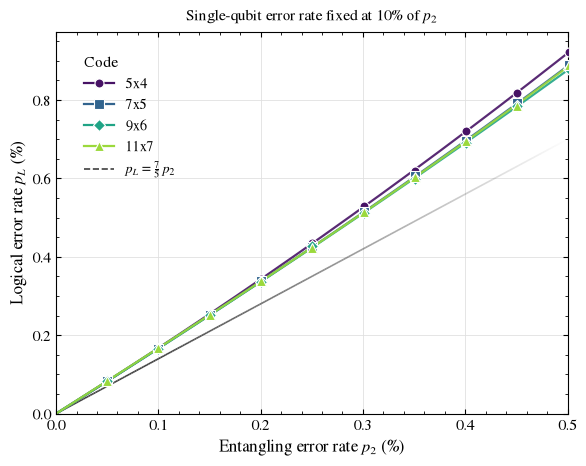

In [70]:
import json
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib import cm

# from your_module import build_circuit   # <- whatever you already import
# CYCLE = ...                             # <- as in your original script

# ============================ USER SETTINGS ============================
CONFIGS = {
    (5, 4):  "config/5x4.json",        # keys are ignored; only the paths are used
    (7, 5):  "config/7x5.json",
    (9, 6):  "config/9x6.json",
    (11, 7): "config/11x7.json",
}
ERROR_MODEL = "error_model.json"
XMAX = 0.5
XMIN = 0.05
P2_PERCENT = np.linspace(XMIN, XMAX + 0.001, 10)   # entangling (p_cnot) error rate, %
SINGLE_QUBIT_RATIO = 0.10                          # every other p_* = 0.10 * p2
TWO_QUBIT_KEYS = {"p_cnot"}
BATCH, MAX_SHOTS, TARGET_FAILS = 1_000, 50_000_000, 10_000
RESULT_PATH = "output/li_sweep_results.json"

# (function of p2 in %, legend label, line style kwargs)
REFERENCE_LINES = [
    (lambda p: (7 / 5) * p, r"$p_L = \frac{7}{5}\,p_2$", dict(color="0.25", lw=1.2, ls="--")),
]
# =======================================================================

base = json.load(open(ERROR_MODEL))
p_keys = [k for k in base if k.startswith("p_")]


def label_of(path):
    """Config name from the file name, e.g. 'config/11x7.json' -> '11x7'."""
    return os.path.splitext(os.path.basename(path))[0]


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return max(c - h, 0.0), min(c + h, 1.0)


def run_point(shape, config_path, p2, seed):
    p1 = SINGLE_QUBIT_RATIO * p2
    model = {k: ((p2 if k in TWO_QUBIT_KEYS else p1) if k in p_keys else v)
             for k, v in base.items()}
    with tempfile.NamedTemporaryFile("w", suffix=".json", delete=False) as f:
        json.dump(model, f)
        model_path = f.name
    try:
        circuit = build_circuit(cycle=CYCLE, ncols=shape[0], nrows=shape[1], config_filepath=config_path, error_model=model_path)
    finally:
        os.remove(model_path)

    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = n_acc = n_fail = 0
    while shots < MAX_SHOTS and n_fail < TARGET_FAILS:
        dets, obs = sampler.sample(BATCH, separate_observables=True)
        acc = ~dets.any(axis=1)
        n_acc += int(acc.sum())
        n_fail += int(obs[acc].any(axis=1).sum())
        shots += BATCH

    ler = n_fail / n_acc if n_acc else np.nan
    lo, hi = wilson(n_fail, n_acc)
    return dict(p2=p2, shots=shots, n_acc=n_acc, n_fail=n_fail,
                acc=n_acc / shots, ler=ler, lo=lo, hi=hi)


# ------------------------------ sweep ------------------------------
# Set to False to re-plot from a previous run without re-simulating.
RUN_SWEEP = False

if RUN_SWEEP:
    results = {}   # label -> list of rows
    for ci, (shape, path) in enumerate(CONFIGS.items()):
        lab = label_of(path)
        print(f"\n[{lab}] shape={shape} {path}")
        rows = []
        for pi, p2_pct in enumerate(P2_PERCENT):
            r = run_point(shape=shape, config_path=path, p2=p2_pct / 100, seed=10_000 * ci + pi)
            rows.append(r)
            print(f"  p2={p2_pct:.2f}%  acc={r['acc']:.3f}  "
                  f"fails={r['n_fail']}/{r['n_acc']}  LER={100 * r['ler']:.4f}%")
        results[lab] = rows
    json.dump(results, open(RESULT_PATH, "w"), indent=1, default=float)
else:
    results = json.load(open(RESULT_PATH))

# ------------------------------ plot ------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 11,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "pdf.fonttype": 42,      # editable text in vector output
})

# Sequential, colour-blind-safe palette: darker = larger code.
n = len(results)
COLORS = [cm.viridis(v) for v in np.linspace(0.05, 0.85, n)]
MARKERS = ["o", "s", "D", "^", "v", "P", "X", "h"]
style = {k: (COLORS[i], MARKERS[i % len(MARKERS)]) for i, k in enumerate(results)}


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, ls="-", fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=ls, zorder=1, **kw)
    ax.add_collection(lc)
    return lc


def draw(ax, xmax, ms=6.5, show_err=True, fade=True):
    handles = []

    # data
    for lab, rows in results.items():
        col, mk = style[lab]
        x = np.array([100 * r["p2"] for r in rows])
        y = np.array([100 * r["ler"] for r in rows])
        lo = np.array([100 * r["lo"] for r in rows])
        hi = np.array([100 * r["hi"] for r in rows])
        ok = np.isfinite(y)

        xs, ys = smooth_curve(x[ok], y[ok], x.max())
        ax.plot(xs, ys, color=col, lw=1.6, alpha=0.9, zorder=2)

        if show_err:
            ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt="none",
                        ecolor=col, elinewidth=1.0, capsize=2.5, capthick=1.0, zorder=3)
        ax.plot(x[ok], y[ok], mk, color=col, ms=ms, mec="white", mew=0.8, zorder=4)

        handles.append(Line2D([], [], color=col, marker=mk, ms=ms, mec="white",
                              mew=0.8, lw=1.6, label=lab))

    # reference lines
    xs_ref = np.linspace(0, xmax, 300)
    for f, lab_ref, kw in REFERENCE_LINES:
        color, lw, ls = kw.get("color", "k"), kw.get("lw", 1.2), kw.get("ls", "--")
        if fade:
            fading_line(ax, xs_ref, f(xs_ref), color=color, lw=lw, ls=ls)
        else:
            ax.plot(xs_ref, f(xs_ref), color=color, lw=lw, ls=ls, zorder=1)
        handles.append(Line2D([], [], color=color, lw=lw, ls=ls, label=lab_ref))

    return handles


fig, ax = plt.subplots(figsize=(6.0, 4.8))
handles = draw(ax, XMAX)

ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])
ax.set_xlim(0, XMAX)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate $p_2$ (%)")
ax.set_ylabel("Logical error rate $p_L$ (%)")
ax.set_title(f"Single-qubit error rate fixed at {int(SINGLE_QUBIT_RATIO * 100)}% of $p_2$",
             pad=8)
ax.grid(True, which="major", color="0.88", lw=0.6, zorder=0)
ax.set_axisbelow(True)

ax.legend(handles=handles, title="Code", frameon=False, loc="upper left",
          bbox_to_anchor=(0.03, 0.97), alignment="left", handlelength=2.2)

fig.tight_layout()
fig.savefig("li_fig_a.png", dpi=300)
fig.savefig("li_fig_a.pdf")          # vector version for LaTeX / reports
plt.show()

In [24]:
# 1) Minimum-weight undetectable logical error (post-selected distance)
err = circuit.search_for_undetectable_logical_errors(
    dont_explore_detection_event_sets_with_size_above=9999,
    dont_explore_edges_with_degree_above=9999,
    dont_explore_edges_increasing_symptom_degree=False,
)
print(len(err))          # should be ~d; 1 or 2 means a bug
for e in err: print(e)   # shows the offending circuit locations

# 2) Direct check for single faults that flip only the observable
dem = circuit.detector_error_model(decompose_errors=False)
for inst in dem.flattened():
    if inst.type == "error":
        t = inst.targets_copy()
        if all(x.is_logical_observable_id() for x in t):
            print(inst)

1
ExplainedError {
    dem_error_terms: L1
    CircuitErrorLocation {
        flipped_pauli_product: Y29[coords 3.5,1]*Z9[coords 3,1]
        Circuit location stack trace:
            (after 9 TICKs)
            at instruction #81 (DEPOLARIZE2) in the circuit
            at targets #9 to #10 of the instruction
            resolving to DEPOLARIZE2(0.001) 29[coords 3.5,1] 9[coords 3,1]
    }
    CircuitErrorLocation {
        flipped_pauli_product: Z29[coords 3.5,1]*Z9[coords 3,1]
        Circuit location stack trace:
            (after 9 TICKs)
            at instruction #81 (DEPOLARIZE2) in the circuit
            at targets #9 to #10 of the instruction
            resolving to DEPOLARIZE2(0.001) 29[coords 3.5,1] 9[coords 3,1]
    }
    CircuitErrorLocation {
        flipped_pauli_product: Z9[coords 3,1]
        Circuit location stack trace:
            (after 8 TICKs)
            at instruction #78 (DEPOLARIZE1) in the circuit
            at target #5 of the instruction
            re

In [12]:
import json, os, tempfile
import numpy as np

CYCLE = ["bZ", "rX", "gZ", "bX"]
SHOTS = 100_000

base = json.load(open("error_model.json"))
p_keys = [k for k in base if k.startswith("p_")]
print("Noise keys found:", {k: base[k] for k in p_keys})

# Which key(s) are the CNOT rate? Edit this list if the auto-detection guesses wrong.
CNOT_KEYS = [k for k in p_keys if any(s in k.lower() for s in ("cnot", "cx", "2q", "two"))]
if not CNOT_KEYS:
    raise ValueError(f"Couldn't identify the CNOT key among {p_keys}; set CNOT_KEYS by hand.")
print("Treating as p_cnot:", CNOT_KEYS, "| everything else = p_cnot / 10")

_tmp = os.path.join(tempfile.mkdtemp(), "model.json")

def build(p_cnot):
    model = {
        k: ((p_cnot if k in CNOT_KEYS else p_cnot / 10) if k.startswith("p_") else v)
        for k, v in base.items()
    }
    json.dump(model, open(_tmp, "w"))
    return build_circuit(cycle=CYCLE, error_model=_tmp)


def per_observable_first_order(circuit, p_ref):
    """First-order undetected-logical coefficient, split by which observables flip."""
    out = {}
    for p, D, O in dem_mechanisms(circuit):
        if not D and O:
            out[tuple(sorted(O))] = out.get(tuple(sorted(O)), 0.0) + p / p_ref
    return out


p_ref = 1e-3
circuit = build(p_ref)
coef = perturbative_postselected_rate(circuit, p_ref)
print(coef)
print(f"p_L(p)  ≈ {coef['A']:.4g}·p + {coef['C']:.4g}·p²")
print(f"P_acc(p) ≈ 1 - {coef['a1']:.4g}·p")
print("First-order coefficient by observable set:", per_observable_first_order(circuit, p_ref))

explain_undetected_logicals(circuit)

# Sanity check vs Monte Carlo across p (including the p that matches your original run)
for p in [3e-4, 1e-3, 3e-3]:
    c = build(p)
    dets, obs = c.compile_detector_sampler(seed=1).sample(SHOTS, separate_observables=True)
    acc = ~dets.any(axis=1)
    n_acc = int(acc.sum())
    n_fail = int(obs[acc].any(axis=1).sum())
    mc = n_fail / n_acc if n_acc else float("nan")
    acc_pred, pL_pred = predict(coef, p)
    print(f"p={p:.0e}  MC p_L={mc:.3e} ({n_fail} fails)  pert p_L={pL_pred:.3e}  "
          f"MC acc={acc.mean():.4f}  pert acc={acc_pred:.4f}")

Noise keys found: {'p_initialisation': 0.0001, 'p_hadamard': 0.0001, 'p_cnot': 0.0001, 'p_measurement': 0.0001, 'p_idling': 0.0001}
Treating as p_cnot: ['p_cnot'] | everything else = p_cnot / 10
{'A': 1.6324093362328846, 'a1': 63.661940470612656, 'B': 40.17192637933846, 'C': 144.09427236626868, 'n_mechs': 68}
p_L(p)  ≈ 1.632·p + 144.1·p²
P_acc(p) ≈ 1 - 63.66·p
First-order coefficient by observable set: {(0,): 0.2666755769053082, (0, 1): 0.20003558164951937, (1,): 1.165698177678057}
ExplainedError {
    dem_error_terms: L0
    CircuitErrorLocation {
        flipped_pauli_product: X8[coords 2,1]
        Circuit location stack trace:
            (after 0 TICKs)
            at instruction #41 (DEPOLARIZE1) in the circuit
            at target #1 of the instruction
            resolving to DEPOLARIZE1(0.0001) 8[coords 2,1]
    }
}
ExplainedError {
    dem_error_terms: L0 L1
    CircuitErrorLocation {
        flipped_pauli_product: Y8[coords 2,1]
        Circuit location stack trace:
       

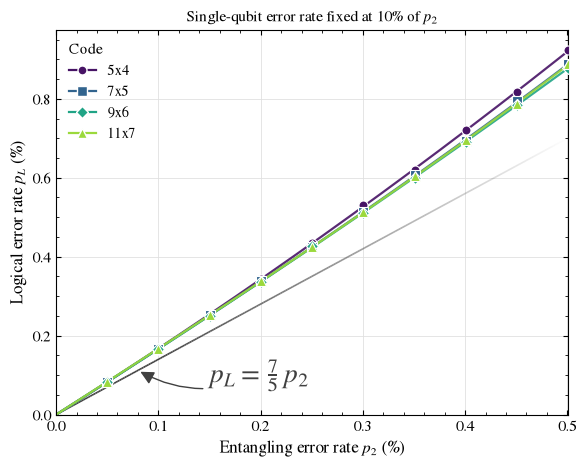

In [66]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

RESULTS_FILE = "li_sweep_results.json"
SINGLE_QUBIT_RATIO = 0.10
RATIO_REF = 7 / 5          # reference line p_L = (7/5) p_2; set to None to hide
REF_LABEL = r"$p_L = \frac{7}{5}\,p_2$"
FADE_FROM, FADE_TO = 0.1, 0.5     # x (%) where the line starts / finishes fading
ANNOT_X = 0.08                    # x (%) on the line the arrow points to (keep in the solid part)
ANNOT_TEXT_POS = (0.30, 0.10)     # label position, in axes fractions (move if it overlaps data)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "pdf.fonttype": 42,
})

results = json.load(open(RESULTS_FILE))   # {label: [ {p2, ler, lo, hi, ...}, ... ]}

n = len(results)
colors = [cm.viridis(v) for v in np.linspace(0.05, 0.85, n)]
markers = ["o", "s", "D", "^", "v", "P", "X", "h"]


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, ls="--", fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=ls, zorder=1, **kw)
    ax.add_collection(lc)
    return lc


fig, ax = plt.subplots(figsize=(6.0, 4.8))
handles = []

for i, (lab, rows) in enumerate(results.items()):
    col, mk = colors[i], markers[i % len(markers)]
    x = np.array([100 * r["p2"] for r in rows])      # % entangling error
    y = np.array([100 * r["ler"] for r in rows])     # % logical error
    lo = np.array([100 * r["lo"] for r in rows])
    hi = np.array([100 * r["hi"] for r in rows])
    ok = np.isfinite(y)

    xs, ys = smooth_curve(x[ok], y[ok], x.max())
    ax.plot(xs, ys, color=col, lw=1.6, alpha=0.9, zorder=2)
    ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt="none",
                ecolor=col, elinewidth=1.0, capsize=2.5, zorder=3)
    ax.plot(x[ok], y[ok], mk, color=col, ms=6.5, mec="white", mew=0.8, zorder=4)
    handles.append(Line2D([], [], color=col, marker=mk, ms=6.5, mec="white",
                          lw=1.6, label=lab))

xmax = max(100 * r["p2"] for rows in results.values() for r in rows)
if RATIO_REF:
    xr = np.linspace(0, xmax, 300)
    fading_line(ax, xr, RATIO_REF * xr, color="0.25", lw=1.2, ls="--",
                fade_from=FADE_FROM, fade_to=FADE_TO)
    ax.annotate(REF_LABEL,
                xy=(ANNOT_X, RATIO_REF * ANNOT_X),
                xytext=ANNOT_TEXT_POS, textcoords="axes fraction",
                color="0.25", fontsize=20, ha="left", va="center",
                arrowprops=dict(arrowstyle="-|>", color="0.25", lw=1.0,
                                shrinkA=3, shrinkB=2,
                                connectionstyle="arc3,rad=-0.25"))

ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])
ax.set_xlim(0, xmax)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate $p_2$ (%)")
ax.set_ylabel("Logical error rate $p_L$ (%)")
ax.set_title(f"Single-qubit error rate fixed at {int(SINGLE_QUBIT_RATIO * 100)}% of $p_2$")
ax.grid(True, color="0.88", lw=0.6)
ax.set_axisbelow(True)
ax.legend(handles=handles, title="Code", frameon=False, loc="upper left",
          alignment="left")

fig.tight_layout()
fig.savefig("li_fig_a.png", dpi=300)
fig.savefig("li_fig_a.pdf")
plt.show()


[5x4] shape=(5, 4) config/5x4.json
  p2=0.05%  acc=0.804  fails=100002/23962070  LER=0.4173%
  p2=0.10%  acc=0.647  fails=100003/11289760  LER=0.8858%
  p2=0.15%  acc=0.521  fails=100005/7188164  LER=1.3912%
  p2=0.20%  acc=0.421  fails=100002/5106536  LER=1.9583%
  p2=0.25%  acc=0.340  fails=100001/3910467  LER=2.5573%
  p2=0.30%  acc=0.276  fails=100000/3117302  LER=3.2079%
  p2=0.35%  acc=0.224  fails=100003/2544771  LER=3.9297%
  p2=0.40%  acc=0.182  fails=100006/2137864  LER=4.6778%
  p2=0.45%  acc=0.148  fails=100002/1827299  LER=5.4727%
  p2=0.50%  acc=0.121  fails=100000/1575549  LER=6.3470%

[7x5] shape=(7, 5) config/7x5.json
  p2=0.05%  acc=0.671  fails=100001/24452972  LER=0.4090%
  p2=0.10%  acc=0.451  fails=100002/11793667  LER=0.8479%
  p2=0.15%  acc=0.304  fails=100000/7625520  LER=1.3114%
  p2=0.20%  acc=0.205  fails=100000/5514061  LER=1.8135%
  p2=0.25%  acc=0.139  fails=100001/4261206  LER=2.3468%
  p2=0.30%  acc=0.094  fails=100001/3443965  LER=2.9037%
  p2=0.35%  

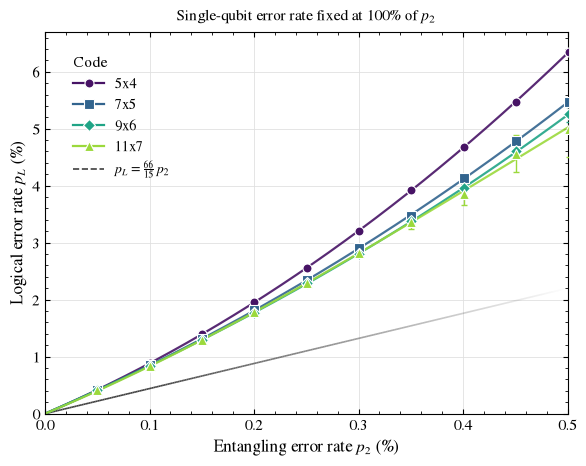

In [65]:
import json
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib import cm

# from your_module import build_circuit   # <- whatever you already import
# CYCLE = ...                             # <- as in your original script

# ============================ USER SETTINGS ============================
CONFIGS = {
    (5, 4):  "config/5x4.json",        # keys are ignored; only the paths are used
    (7, 5):  "config/7x5.json",
    (9, 6):  "config/9x6.json",
    (11, 7): "config/11x7.json",
}
ERROR_MODEL = "error_model.json"
XMAX = 0.5
XMIN = 0.05
P2_PERCENT = np.linspace(XMIN, XMAX + 0.001, 10)   # entangling (p_cnot) error rate, %
SINGLE_QUBIT_RATIO = 1                          # every other p_* = 0.10 * p2
TWO_QUBIT_KEYS = {"p_cnot"}
BATCH, MAX_SHOTS, TARGET_FAILS = 1_000, 50_000_000, 100_000

# (function of p2 in %, legend label, line style kwargs)
REFERENCE_LINES = [
    (lambda p: (66 / 15) * p, r"$p_L = \frac{66}{15}\,p_2$", dict(color="0.25", lw=1.2, ls="--")),
]
# =======================================================================

base = json.load(open(ERROR_MODEL))
p_keys = [k for k in base if k.startswith("p_")]


def label_of(path):
    """Config name from the file name, e.g. 'config/11x7.json' -> '11x7'."""
    return os.path.splitext(os.path.basename(path))[0]


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return max(c - h, 0.0), min(c + h, 1.0)


def run_point(shape, config_path, p2, seed):
    p1 = SINGLE_QUBIT_RATIO * p2
    model = {k: ((p2 if k in TWO_QUBIT_KEYS else p1) if k in p_keys else v)
             for k, v in base.items()}
    with tempfile.NamedTemporaryFile("w", suffix=".json", delete=False) as f:
        json.dump(model, f)
        model_path = f.name
    try:
        circuit = build_circuit(cycle=CYCLE, ncols=shape[0], nrows=shape[1],
                                config_filepath=config_path, error_model=model_path)
    finally:
        os.remove(model_path)

    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = n_acc = n_fail = 0
    while shots < MAX_SHOTS and n_fail < TARGET_FAILS:
        dets, obs = sampler.sample(BATCH, separate_observables=True)
        acc = ~dets.any(axis=1)
        n_acc += int(acc.sum())
        n_fail += int(obs[acc].any(axis=1).sum())
        shots += BATCH

    ler = n_fail / n_acc if n_acc else np.nan
    lo, hi = wilson(n_fail, n_acc)
    return dict(p2=p2, shots=shots, n_acc=n_acc, n_fail=n_fail,
                acc=n_acc / shots, ler=ler, lo=lo, hi=hi)


# ------------------------------ sweep ------------------------------
# Set to False to re-plot from a previous run without re-simulating.
RUN_SWEEP = True

if RUN_SWEEP:
    results = {}   # label -> list of rows
    for ci, (shape, path) in enumerate(CONFIGS.items()):
        lab = label_of(path)
        print(f"\n[{lab}] shape={shape} {path}")
        rows = []
        for pi, p2_pct in enumerate(P2_PERCENT):
            r = run_point(shape=shape, config_path=path, p2=p2_pct / 100, seed=10_000 * ci + pi)
            rows.append(r)
            print(f"  p2={p2_pct:.2f}%  acc={r['acc']:.3f}  "
                  f"fails={r['n_fail']}/{r['n_acc']}  LER={100 * r['ler']:.4f}%")
        results[lab] = rows
    json.dump(results, open("li_sweep_no_idle.json", "w"), indent=1, default=float)
else:
    results = json.load(open("li_sweep_no_idle.json"))

# ------------------------------ plot ------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 11,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "pdf.fonttype": 42,      # editable text in vector output
})

# Sequential, colour-blind-safe palette: darker = larger code.
n = len(results)
COLORS = [cm.viridis(v) for v in np.linspace(0.05, 0.85, n)]
MARKERS = ["o", "s", "D", "^", "v", "P", "X", "h"]
style = {k: (COLORS[i], MARKERS[i % len(MARKERS)]) for i, k in enumerate(results)}


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, ls="-", fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=ls, zorder=1, **kw)
    ax.add_collection(lc)
    return lc


def draw(ax, xmax, ms=6.5, show_err=True, fade=True):
    handles = []

    # data
    for lab, rows in results.items():
        col, mk = style[lab]
        x = np.array([100 * r["p2"] for r in rows])
        y = np.array([100 * r["ler"] for r in rows])
        lo = np.array([100 * r["lo"] for r in rows])
        hi = np.array([100 * r["hi"] for r in rows])
        ok = np.isfinite(y)

        xs, ys = smooth_curve(x[ok], y[ok], x.max())
        ax.plot(xs, ys, color=col, lw=1.6, alpha=0.9, zorder=2)

        if show_err:
            ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt="none",
                        ecolor=col, elinewidth=1.0, capsize=2.5, capthick=1.0, zorder=3)
        ax.plot(x[ok], y[ok], mk, color=col, ms=ms, mec="white", mew=0.8, zorder=4)

        handles.append(Line2D([], [], color=col, marker=mk, ms=ms, mec="white",
                              mew=0.8, lw=1.6, label=lab))

    # reference lines
    xs_ref = np.linspace(0, xmax, 300)
    for f, lab_ref, kw in REFERENCE_LINES:
        color, lw, ls = kw.get("color", "k"), kw.get("lw", 1.2), kw.get("ls", "--")
        if fade:
            fading_line(ax, xs_ref, f(xs_ref), color=color, lw=lw, ls=ls)
        else:
            ax.plot(xs_ref, f(xs_ref), color=color, lw=lw, ls=ls, zorder=1)
        handles.append(Line2D([], [], color=color, lw=lw, ls=ls, label=lab_ref))

    return handles


fig, ax = plt.subplots(figsize=(6.0, 4.8))
handles = draw(ax, XMAX)

ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])
ax.set_xlim(0, XMAX)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate $p_2$ (%)")
ax.set_ylabel("Logical error rate $p_L$ (%)")
ax.set_title(f"Single-qubit error rate fixed at {int(SINGLE_QUBIT_RATIO * 100)}% of $p_2$",
             pad=8)
ax.grid(True, which="major", color="0.88", lw=0.6, zorder=0)
ax.set_axisbelow(True)

ax.legend(handles=handles, title="Code", frameon=False, loc="upper left",
          bbox_to_anchor=(0.03, 0.97), alignment="left", handlelength=2.2)

fig.tight_layout()
fig.savefig("li_fig_a.png", dpi=300)
fig.savefig("li_fig_a.pdf")          # vector version for LaTeX / reports
plt.show()

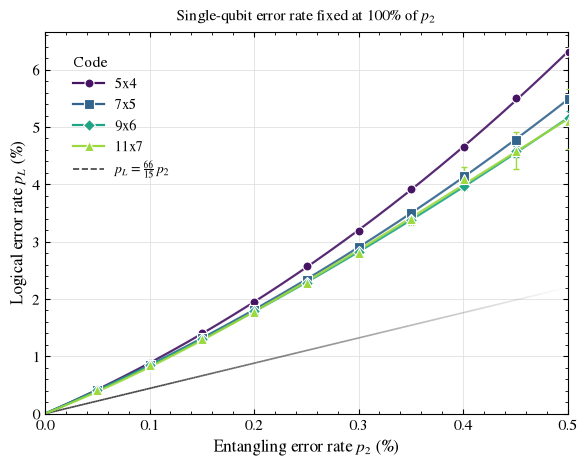

In [57]:
import json
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib import cm

# from your_module import build_circuit   # <- whatever you already import
# CYCLE = ...                             # <- as in your original script

# ============================ USER SETTINGS ============================
CONFIGS = {
    (5, 4):  "config/5x4.json",        # keys are ignored; only the paths are used
    (7, 5):  "config/7x5.json",
    (9, 6):  "config/9x6.json",
    (11, 7): "config/11x7.json",
}
ERROR_MODEL = "error_model.json"
XMAX = 0.5
XMIN = 0.01
# P2_PERCENT = np.linspace(XMIN, XMAX + 0.001, 20)   # entangling (p_cnot) error rate, %
P2_PERCENT = np.logspace(np.log10(XMIN), np.log10(XMAX + 0.001), 20)
SINGLE_QUBIT_RATIO = 1                          # every other p_* = 0.10 * p2
TWO_QUBIT_KEYS = {"p_cnot"}
BATCH, MAX_SHOTS, TARGET_FAILS = 1_000_000, 50_000_000, 100_000

# (function of p2 in %, legend label, line style kwargs)
REFERENCE_LINES = [
    (lambda p: (66 / 15) * p, r"$p_L = \frac{66}{15}\,p_2$", dict(color="0.25", lw=1.2, ls="--")),
]
# =======================================================================

base = json.load(open(ERROR_MODEL))
p_keys = [k for k in base if k.startswith("p_")]


def label_of(path):
    """Config name from the file name, e.g. 'config/11x7.json' -> '11x7'."""
    return os.path.splitext(os.path.basename(path))[0]


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return max(c - h, 0.0), min(c + h, 1.0)


def run_point(shape, config_path, p2, seed):
    p1 = SINGLE_QUBIT_RATIO * p2
    model = {k: ((p2 if k in TWO_QUBIT_KEYS else p1) if k in p_keys else v)
             for k, v in base.items()}
    with tempfile.NamedTemporaryFile("w", suffix=".json", delete=False) as f:
        json.dump(model, f)
        model_path = f.name
    try:
        circuit = build_circuit(cycle=CYCLE, ncols=shape[0], nrows=shape[1],
                                config_filepath=config_path, error_model=model_path)
    finally:
        os.remove(model_path)

    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = n_acc = n_fail = 0
    while shots < MAX_SHOTS and n_fail < TARGET_FAILS:
        dets, obs = sampler.sample(BATCH, separate_observables=True)
        acc = ~dets.any(axis=1)
        n_acc += int(acc.sum())
        n_fail += int(obs[acc].any(axis=1).sum())
        shots += BATCH

    ler = n_fail / n_acc if n_acc else np.nan
    lo, hi = wilson(n_fail, n_acc)
    return dict(p2=p2, shots=shots, n_acc=n_acc, n_fail=n_fail,
                acc=n_acc / shots, ler=ler, lo=lo, hi=hi)


# ------------------------------ sweep ------------------------------
# Set to False to re-plot from a previous run without re-simulating.
RUN_SWEEP = False

if RUN_SWEEP:
    results = {}   # label -> list of rows
    for ci, (shape, path) in enumerate(CONFIGS.items()):
        lab = label_of(path)
        print(f"\n[{lab}] shape={shape} {path}")
        rows = []
        for pi, p2_pct in enumerate(P2_PERCENT):
            r = run_point(shape=shape, config_path=path, p2=p2_pct / 100, seed=10_000 * ci + pi)
            rows.append(r)
            print(f"  p2={p2_pct:.2f}%  acc={r['acc']:.3f}  "
                  f"fails={r['n_fail']}/{r['n_acc']}  LER={100 * r['ler']:.4f}%")
        results[lab] = rows
    json.dump(results, open("li_sweep_results_err.json", "w"), indent=1, default=float)
else:
    results = json.load(open("li_sweep_results_err.json"))

# ------------------------------ plot ------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 11,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "pdf.fonttype": 42,      # editable text in vector output
})

# Sequential, colour-blind-safe palette: darker = larger code.
n = len(results)
COLORS = [cm.viridis(v) for v in np.linspace(0.05, 0.85, n)]
MARKERS = ["o", "s", "D", "^", "v", "P", "X", "h"]
style = {k: (COLORS[i], MARKERS[i % len(MARKERS)]) for i, k in enumerate(results)}


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, ls="-", fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=ls, zorder=1, **kw)
    ax.add_collection(lc)
    return lc


def draw(ax, xmax, ms=6.5, show_err=True, fade=True):
    handles = []

    # data
    for lab, rows in results.items():
        col, mk = style[lab]
        x = np.array([100 * r["p2"] for r in rows])
        y = np.array([100 * r["ler"] for r in rows])
        lo = np.array([100 * r["lo"] for r in rows])
        hi = np.array([100 * r["hi"] for r in rows])
        ok = np.isfinite(y)

        xs, ys = smooth_curve(x[ok], y[ok], x.max())
        ax.plot(xs, ys, color=col, lw=1.6, alpha=0.9, zorder=2)

        if show_err:
            ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt="none",
                        ecolor=col, elinewidth=1.0, capsize=2.5, capthick=1.0, zorder=3)
        ax.plot(x[ok], y[ok], mk, color=col, ms=ms, mec="white", mew=0.8, zorder=4)

        handles.append(Line2D([], [], color=col, marker=mk, ms=ms, mec="white",
                              mew=0.8, lw=1.6, label=lab))

    # reference lines
    xs_ref = np.linspace(0, xmax, 300)
    for f, lab_ref, kw in REFERENCE_LINES:
        color, lw, ls = kw.get("color", "k"), kw.get("lw", 1.2), kw.get("ls", "--")
        if fade:
            fading_line(ax, xs_ref, f(xs_ref), color=color, lw=lw, ls=ls)
        else:
            ax.plot(xs_ref, f(xs_ref), color=color, lw=lw, ls=ls, zorder=1)
        handles.append(Line2D([], [], color=color, lw=lw, ls=ls, label=lab_ref))

    return handles


fig, ax = plt.subplots(figsize=(6.0, 4.8))
handles = draw(ax, XMAX)

ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])
ax.set_xlim(0, XMAX)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate $p_2$ (%)")
ax.set_ylabel("Logical error rate $p_L$ (%)")
ax.set_title(f"Single-qubit error rate fixed at {int(SINGLE_QUBIT_RATIO * 100)}% of $p_2$",
             pad=8)
ax.grid(True, which="major", color="0.88", lw=0.6, zorder=0)
ax.set_axisbelow(True)

ax.legend(handles=handles, title="Code", frameon=False, loc="upper left",
          bbox_to_anchor=(0.03, 0.97), alignment="left", handlelength=2.2)

fig.tight_layout()
fig.savefig("li_fig_a.png", dpi=300)
fig.savefig("li_fig_a.pdf")
plt.show()

In [41]:
XMIN = 0.001
XMAX = 0.5

print(np.logspace(np.log10(XMIN), np.log10(XMAX + 0.001), 20))

[0.001      0.00138706 0.00192395 0.00266864 0.00370158 0.00513433
 0.00712165 0.00987818 0.01370168 0.01900511 0.02636132 0.03656486
 0.05071783 0.07034891 0.09757849 0.13534769 0.187736   0.26040198
 0.3611944  0.501     ]


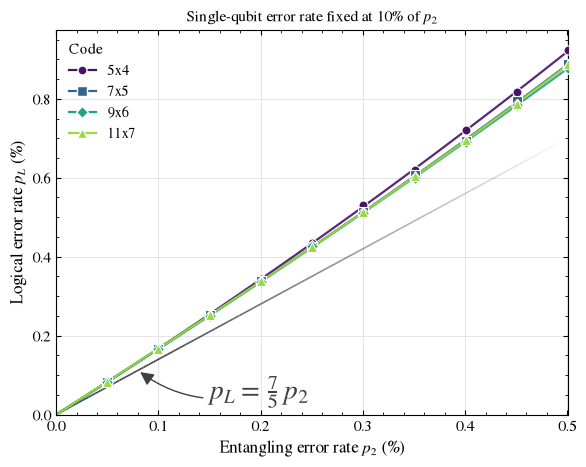

In [64]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

RESULTS_FILE = "li_sweep_results.json"
SINGLE_QUBIT_RATIO = 0.1
RATIO_REF = 7 / 5          # reference line p_L = (7/5) p_2; set to None to hide
REF_LABEL = r"$p_L = \frac{7}{5}\,p_2$"
FADE_FROM, FADE_TO = 0.1, 0.5     # x (%) where the line starts / finishes fading
ANNOT_X = 0.08                    # x (%) on the line the arrow points to (keep in the solid part)
ANNOT_TEXT_POS = (0.30, 0.10)     # label position, in axes fractions (move if it overlaps data)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "pdf.fonttype": 42,
})

results = json.load(open(RESULTS_FILE))   # {label: [ {p2, ler, lo, hi, ...}, ... ]}

n = len(results)
colors = [cm.viridis(v) for v in np.linspace(0.05, 0.85, n)]
markers = ["o", "s", "D", "^", "v", "P", "X", "h"]


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, ls="--", fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=ls, zorder=1, **kw)
    ax.add_collection(lc)
    return lc


fig, ax = plt.subplots(figsize=(6.0, 4.8))
handles = []

for i, (lab, rows) in enumerate(results.items()):
    col, mk = colors[i], markers[i % len(markers)]
    x = np.array([100 * r["p2"] for r in rows])      # % entangling error
    y = np.array([100 * r["ler"] for r in rows])     # % logical error
    lo = np.array([100 * r["lo"] for r in rows])
    hi = np.array([100 * r["hi"] for r in rows])
    ok = np.isfinite(y)

    xs, ys = smooth_curve(x[ok], y[ok], x.max())
    ax.plot(xs, ys, color=col, lw=1.6, alpha=0.9, zorder=2)
    ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt="none",
                ecolor=col, elinewidth=1.0, capsize=2.5, zorder=3)
    ax.plot(x[ok], y[ok], mk, color=col, ms=6.5, mec="white", mew=0.8, zorder=4)
    handles.append(Line2D([], [], color=col, marker=mk, ms=6.5, mec="white",
                          lw=1.6, label=lab))

xmax = max(100 * r["p2"] for rows in results.values() for r in rows)
if RATIO_REF:
    xr = np.linspace(0, xmax, 300)
    fading_line(ax, xr, RATIO_REF * xr, color="0.25", lw=1.2, ls="--",
                fade_from=FADE_FROM, fade_to=FADE_TO)
    ax.annotate(REF_LABEL,
                xy=(ANNOT_X, RATIO_REF * ANNOT_X),
                xytext=ANNOT_TEXT_POS, textcoords="axes fraction",
                color="0.25", fontsize=20, ha="left", va="top",
                arrowprops=dict(arrowstyle="-|>", color="0.25", lw=1.0,
                                shrinkA=3, shrinkB=2,
                                connectionstyle="arc3,rad=-0.25"))

ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])

# ax.set_xscale("log")
# ax.set_yscale("log")

ax.set_xlim(0, xmax)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate $p_2$ (%)")
ax.set_ylabel("Logical error rate $p_L$ (%)")
ax.set_title(f"Single-qubit error rate fixed at {int(SINGLE_QUBIT_RATIO * 100)}% of $p_2$")
ax.grid(True, color="0.88", lw=0.6)
ax.set_axisbelow(True)
ax.legend(handles=handles, title="Code", frameon=False, loc="upper left",
          alignment="left")

fig.tight_layout()
fig.savefig("li_fig_a.png", dpi=300)
fig.savefig("li_fig_a.pdf")
plt.show()

# Phenomenological

In [ ]:
from phenom_honeycomb import PhenomenologicalHoneycomb, PhenomenologicalNoise  # <- adjust module name

# ============================ USER SETTINGS ============================
CONFIGS = {
    (5, 4):  "config/5x4.json",
    (7, 5):  "config/7x5.json",
    (9, 6):  "config/9x6.json",
    (11, 7): "config/11x7.json",
}
XMAX = 5
XMIN = 0.05
P2_PERCENT = np.linspace(XMIN, XMAX + 0.001, 10)   # two-body measurement error rate, %
DATA_RATIO = 0.10        # p_data = DATA_RATIO * p2
MEAS_RATIO = 1.0         # p_meas = MEAS_RATIO * p2
IDEAL_CYCLE = ("bZ", "rX", "gZ", "bX")
NOISY_CYCLE = ("rZ", "gX", "bZ", "rX", "gZ", "bX")
BATCH, MAX_SHOTS, TARGET_FAILS = 1_000, 50_000_000, 10_000
RESULT_PATH = "output/li_sweep_results.json"
# (reference lines unchanged)
# =======================================================================

base = json.load(open(ERROR_MODEL))
p_keys = [k for k in base if k.startswith("p_")]


def label_of(path):
    """Config name from the file name, e.g. 'config/11x7.json' -> '11x7'."""
    return os.path.splitext(os.path.basename(path))[0]


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return max(c - h, 0.0), min(c + h, 1.0)


def run_point(shape, config_path, p2, seed):
    noise = PhenomenologicalNoise(p_data=DATA_RATIO * p2, p_meas=MEAS_RATIO * p2)
    circuit = PhenomenologicalHoneycomb.build_injection_circuit(
        noise,
        ncols=shape[0], nrows=shape[1],
        config_filepath=config_path,
        ideal_cycle=IDEAL_CYCLE, noisy_cycle=NOISY_CYCLE,
    )

    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = n_acc = n_fail = 0
    while shots < MAX_SHOTS and n_fail < TARGET_FAILS:
        dets, obs = sampler.sample(BATCH, separate_observables=True)
        acc = ~dets.any(axis=1)
        n_acc += int(acc.sum())
        n_fail += int(obs[acc].any(axis=1).sum())
        shots += BATCH

    ler = n_fail / n_acc if n_acc else np.nan
    lo, hi = wilson(n_fail, n_acc)
    return dict(p2=p2, shots=shots, n_acc=n_acc, n_fail=n_fail,
                acc=n_acc / shots, ler=ler, lo=lo, hi=hi)


# ------------------------------ sweep ------------------------------
# Set to False to re-plot from a previous run without re-simulating.
RUN_SWEEP = False

if RUN_SWEEP:
    results = {}   # label -> list of rows
    for ci, (shape, path) in enumerate(CONFIGS.items()):
        lab = label_of(path)
        print(f"\n[{lab}] shape={shape} {path}")
        rows = []
        for pi, p2_pct in enumerate(P2_PERCENT):
            r = run_point(shape=shape, config_path=path, p2=p2_pct / 100, seed=10_000 * ci + pi)
            rows.append(r)
            print(f"  p2={p2_pct:.2f}%  acc={r['acc']:.3f}  "
                  f"fails={r['n_fail']}/{r['n_acc']}  LER={100 * r['ler']:.4f}%")
        results[lab] = rows
    json.dump(results, open("li_sweep_results_err.json", "w"), indent=1, default=float)
else:
    results = json.load(open("li_sweep_results_err.json"))

# ------------------------------ plot ------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 11,
    "legend.fontsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "pdf.fonttype": 42,      # editable text in vector output
})

# Sequential, colour-blind-safe palette: darker = larger code.
n = len(results)
COLORS = [cm.viridis(v) for v in np.linspace(0.05, 0.85, n)]
MARKERS = ["o", "s", "D", "^", "v", "P", "X", "h"]
style = {k: (COLORS[i], MARKERS[i % len(MARKERS)]) for i, k in enumerate(results)}


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, ls="-", fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=ls, zorder=1, **kw)
    ax.add_collection(lc)
    return lc


def draw(ax, xmax, ms=6.5, show_err=True, fade=True):
    handles = []

    # data
    for lab, rows in results.items():
        col, mk = style[lab]
        x = np.array([100 * r["p2"] for r in rows])
        y = np.array([100 * r["ler"] for r in rows])
        lo = np.array([100 * r["lo"] for r in rows])
        hi = np.array([100 * r["hi"] for r in rows])
        ok = np.isfinite(y)

        xs, ys = smooth_curve(x[ok], y[ok], x.max())
        ax.plot(xs, ys, color=col, lw=1.6, alpha=0.9, zorder=2)

        if show_err:
            ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt="none",
                        ecolor=col, elinewidth=1.0, capsize=2.5, capthick=1.0, zorder=3)
        ax.plot(x[ok], y[ok], mk, color=col, ms=ms, mec="white", mew=0.8, zorder=4)

        handles.append(Line2D([], [], color=col, marker=mk, ms=ms, mec="white",
                              mew=0.8, lw=1.6, label=lab))

    # reference lines
    xs_ref = np.linspace(0, xmax, 300)
    for f, lab_ref, kw in REFERENCE_LINES:
        color, lw, ls = kw.get("color", "k"), kw.get("lw", 1.2), kw.get("ls", "--")
        if fade:
            fading_line(ax, xs_ref, f(xs_ref), color=color, lw=lw, ls=ls)
        else:
            ax.plot(xs_ref, f(xs_ref), color=color, lw=lw, ls=ls, zorder=1)
        handles.append(Line2D([], [], color=color, lw=lw, ls=ls, label=lab_ref))

    return handles


fig, ax = plt.subplots(figsize=(6.0, 4.8))
handles = draw(ax, XMAX)

ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])
ax.set_xlim(0, XMAX)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate $p_2$ (%)")
ax.set_ylabel("Logical error rate $p_L$ (%)")
ax.set_title(f"Single-qubit error rate fixed at {int(SINGLE_QUBIT_RATIO * 100)}% of $p_2$",
             pad=8)
ax.grid(True, which="major", color="0.88", lw=0.6, zorder=0)
ax.set_axisbelow(True)

ax.legend(handles=handles, title="Code", frameon=False, loc="upper left",
          bbox_to_anchor=(0.03, 0.97), alignment="left", handlelength=2.2)

fig.tight_layout()
fig.savefig("li_fig_a.png", dpi=300)
fig.savefig("li_fig_a.pdf")
plt.show()